# 8.MovimientoRotacional
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


**Carga primero las imágenes corriendo la siguiente linea de código**

In [ ]:
#@title
from google.colab import files
from IPython.display import Image
uploaded=files.upload()

Saving Rotacional1.png to Rotacional1.png
Saving Rotacional2.png to Rotacional2.png
Saving Rotacional3.png to Rotacional3.png
Saving Rotacional4.png to Rotacional4.png
Saving Rotacional5.png to Rotacional5.png
Saving Rotacional6.png to Rotacional6.png
Saving Rotacional7.png to Rotacional7.png
Saving Rotacional8.png to Rotacional8.png
Saving Rotacional9.png to Rotacional9.png
Saving Rotacional10.png to Rotacional10.png
Saving Rotacional11.png to Rotacional11.png
Saving Rotacional12.png to Rotacional12.png
Saving Rotacional13.png to Rotacional13.png
Saving Rotacional14.png to Rotacional14.png
Saving Totacional15.png to Totacional15.png


In [ ]:
import matplotlib.pyplot as plt              # Paquete gráfico de matplotlib 
import matplotlib as mpl
from mpl_toolkits.mplot3d import Axes3D      # Proyección 3D con matplotlib 
from sympy import *                          # Se importan todas las funciones del paquete sympy
init_printing()                              # Mejora la impresión visual de los resultados arrojados por sympy
import numpy as np                           # Trae las funciones del paquete numpy llamandolas a través del prefijo np
from IPython.display import display, Math    # Imprimir resultados en latex


x,y,z,alpha,omega=symbols('x,y,z,alpha,omega')   # Parámetros algebraicos para sympy

m_p = 1        # Masa de la partícula en ua
h_b = 1        # hbar reducida en ua
r=1            # Distancia radial en ua 
I=m_p*r**2     # Momento de inercia
w=np.linspace(0,2*np.pi,150)       # Vector sobre el que toma valores la función de onda

# Función de energía para un estado de un anillo circular.

def EnergiaA(m):
    return (m**2*h_b**2)/(2*I) 

# Gráfico de la parte real de las funciones de onda para los diferentes estados de una partícula en un anillo circular, acompañadas del valor de energía

def GfunOA(m):
    f=(1/(2*np.pi))*np.cos(m*w)
    plt.plot(w,f,label='$Re(\Theta_{:d}$)'.format(m))
    plt.legend()
    plt.title('Parte real de la función de onda')
    display(Math('E_{}={}'.format(m,EnergiaA(m)))) 
    display(Math('\Theta_{}(\N{greek small letter theta})=(\sqrt2/2\sqrt\pi)[cos({}\N{greek small letter theta})+isen({}\N{greek small letter theta})]'.format(m,m,m)))


# Gráfico de los valores de energía desde 0 hasta m

def EnergiaGA(m):
    for i in range(0,m+1):
        Ei=(i**2*h_b**2)/(2*I)
        print('m=',i,',',-i,';','E=',Ei)
        plt.plot(w,Ei+(w-w),label='$E_{:d}$'.format(i))
        plt.title('Valores de energía')
        plt.ylabel('Energía (Hartree)')
        plt.legend()
        
# Gráfico de la parte real de la función de onda en el perímetro del anillo,
# junto con su función de densidad de probabilidad.

def GfunOAC(m):
    mpl.rcParams['legend.fontsize'] = 15
    theta = np.linspace(0, 2 * np.pi, 150)
    z = ((1/(2*np.pi))**0.5)*np.cos(m*theta)
    z1=0
    z2=1/(2*np.pi)
    x = 5 * np.sin(theta)
    y = 5 * np.cos(theta)
    
    fig, ax = plt.subplots(subplot_kw=dict(projection='3d'), figsize=(12,10))
    im = ax.plot(x, y, z1, label='Anillo')
    im = ax.plot(x, y, z, label='$Re(\Theta_{:d})$'.format(m))    
    im = ax.plot(x, y, z2, label='$|\Theta_{:d}|^2$'.format(m))
    ax.legend()

# Movimiento Rotacional

Si consideramos un objeto rígido girando alrededor de un eje fijo, cada punto de este objeto se moverá en una circunferencia con centro el eje de rotación y radio la distancia del punto al eje. Si tomamos cualquier par de puntos del objeto y dibujamos sus radios, estos radios barrerán ángulos iguales en tiempos iguales sin importar que tan distantes esten del eje de rotación. Para ilustrar esta situación observemos el siguiente disco que está rotando alrededor de su eje de simetría.

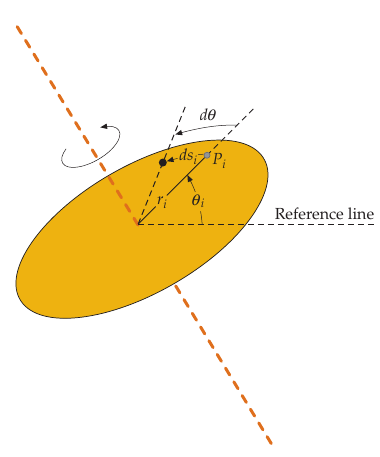

In [ ]:
#@title
Image(filename='disco.png', width=400, height=500)
# Figura tomada de: Tipler P. y Mosca G. Physics for Scientists and Engineers, 2008.

En la figura $r_i$ es la distancia desde el eje de rotación al punto del disco $P_i$ y $\theta_i$ es el ángulo inicial que forma la linea radial que pasa por $r_i$ con respecto a una linea de referencia (medido en la dirección contraria de las manecillas del reloj). Si el disco rota un ángulo $d\theta$, la partícula $P_i$ se desplaza a lo largo de un arco circular de longitud $ds_i$, de tal forma que $d\theta=ds_i/r_i$. El ángulo inicial $\theta_i$, la longitud $ds_i$ y el radio $r_i$ varian de partícula en partícula, pero el valor $d\theta=ds_i/r_i$, llamado $\textbf{desplazamiento angular}$, es el mismo para todas las partículas del disco. Por ejemplo, para una revolución completa podemos hacer la siguiente cuenta:

$$variación \  de  \  \theta:  \ \Delta\theta=\frac{\Delta s_i}{r_i}=\frac{2\pi r_i}{r_i}=2\pi$$

En general, la tasa de cambio del ángulo de rotación con respecto al tiempo es la misma para cualquier partícula sobre el disco. Esta tasa de cambio se denota por $\omega=d\theta/dt$ y se llama $\textbf{velocidad angular}$. Si la dirección de rotación es contraria a las manecillas del reloj se designa como positiva, entonces $d\theta$ es una cantidad positiva y por lo tanto $\omega$. Bajo las mismas condiciones, si el disco gira en la dirección de la manecillas del reloj $\omega$ es negativa. En el sistema internacional de medidas las unidades de $\omega$ son $rad/s$.

Para el movimiento rotacional la $\textbf{aceleración angular}$ $\alpha$ se define como la tasa de cambio de la velocidad angular, es decir, $\alpha=\frac{d\omega}{dt}=\frac{d^2\theta}{dt^2}$. La aceleración angular será positiva si $\omega$ incrementa y negativa si $\omega$ disminuye. En el movimiento rotacional: el desplazamiento angular $\theta$, la velocidad angular $\omega$ y la aceleración angular $\alpha$, son los análogos al desplazamiento lineal $x$, la velocidad lineal $v$ y la aceleración lineal $a$, del movimiento uni-dimensional.

Para un objeto rígido en rotación su energía cinética estará dada por la sumatoria de las energía cinéticas de cada una de las partículas de masa $m_i$ que lo conforman. Si $\frac{1}{2}m_iv_i^2$ es la energía cinética de la partícula $i$-ésima, la energía cinética del objeto será $K=\sum_i \frac{1}{2}m_iv_i^2 $. Como la velocidad lineal la partícula $i$-ésima es $v_i=\frac{ds_i}{dt}=\frac{r_id\theta}{dt}=r_i\omega$, la energía cinética se puede expresar como

$$K=\sum_i \frac{1}{2}m_iv_i^2=\sum_i \frac{1}{2}m_ir_i^2\omega^2= \frac{1}{2}(\sum_i m_ir_i^2)\omega^2=\frac{1}{2}I\omega^2 $$

donde $I=(\sum_i m_ir_i^2)$ es el $\textbf{momento de inercia}$ con respecto al eje de rotación. En el movimiento rotacional el momento de inercia $I$ desempeña un papel análogo al de la masa inercial $m$ en el caso del movimiento rectilíneo. Este puede pensarse como la medida de la resistencia que opone un cuerpo a los cambios en su movimiento rotacional alrededor de un eje. Entre más lejos se encuentre una masa del eje de rotación es más grande su contribución al momento de inercía alrededor del eje, por ello el momento de inercia depende tanto de la localización del eje de rotación como de la masa. Como vemos en el movimiento rotacional el momento de inercia $I$ es el analogo a la masa inercial $m$ del movimiento rectílineo. De acuerdo a esta correspondencia podemos definir el $\textbf{momento angular}$ $L$ como $L=I\omega$ como el análogo del momento lineal $p=mv$.

En ambas situaciones la energía cinética se puede escribir en términos del momento, como sigue:

$$ momento \ lineal: \ \ K=\frac{1}{2}mv^2=\frac{(mv)^2}{2m}=\frac{p^2}{2m}  \  \  \  \  \ \ \ momento \ angular: \ \  K=\frac{1}{2}I\omega^2=\frac{(I\omega)^2}{2I}=\frac{L^2}{2I} $$

La correspondencia entre estas cantidades se muestra en la siguiente tabla:

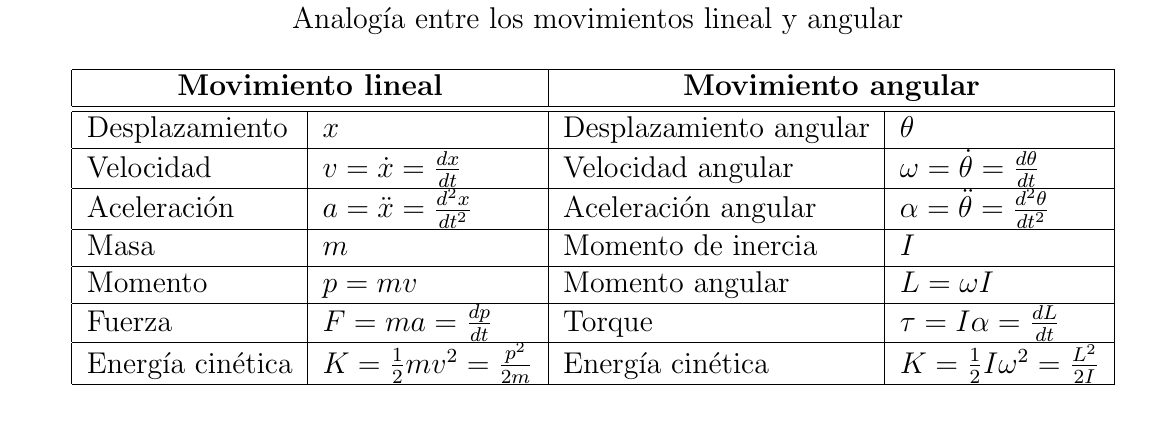

In [ ]:
#@title
Image(filename='tablaLA.png', width=950, height=360)

En la tabla anterior todas las cantidades son vectoriales, excepto la masa y la energía que son cantidades escalares. El momento angular se define en general por
$\overrightarrow{L}=\overrightarrow{r}\times \overrightarrow{p}$, el cual tiene como componentes:

$$\overrightarrow{L}=\overrightarrow{r}\times \overrightarrow{p}=\left|
\begin{array}{ccc}
\hat{i}   &    \hat{j}  &  \hat{k} \\
x  &  y  &  z   \\
p_x & p_y & p_z  
\end{array}
\right|=(yp_z-zp_y)\hat{i}+(zp_x-xp_z)\hat{j}+(xp_y-yp_x)\hat{k}$$

Como $\overrightarrow{p}=m\overrightarrow{v}$, tenemos que $\overrightarrow{L}=m\overrightarrow{r}\times \overrightarrow{v}$. En general, el ángulo que forman los vectores posición y velocidad es de $\frac{\pi}{2}$ y por ello $\overrightarrow{L}=mrvsen(\frac{\pi}{2})\hat{l}=mrv\hat{l}$, donde $\hat{l}$ es un vector unitario ortogonal a $\overrightarrow{r}\times \overrightarrow{v}$. Observe la sigiente figura en la que una masa $m$ gira en un disco circular cuyo plano contiene al vector posición $\overrightarrow{r}$.

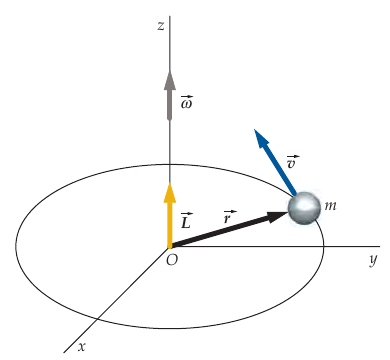

In [ ]:
#@title
Image(filename='angular.png', width=400, height=400)
# Figura tomada de: Tipler P. y Mosca G. Physics for Scientists and Engineers, 2008.

En este caso $\hat{l}=\hat{k}$ y por lo tanto $\overrightarrow{L}=mrv\hat{k}=mr^2\omega\hat{k}=mr^2\overrightarrow{\omega}=I\overrightarrow{\omega}$, es decir, el vector de momento angular se dirige en la dirección del vector velocidad angular $\overrightarrow{\omega}$. Este hecho se tiene en general para cualquier configuración de partículas que giran alrededor de un eje de simetría.

De acuerdo con el segundo postulado de la mecánica cuántica:

$\textbf{a cada observable de la mecánica clásica le corresponde un operador mecánico-cuántico}$

esta correspondencia la podemos ejemplificar en la siguiente tabla:

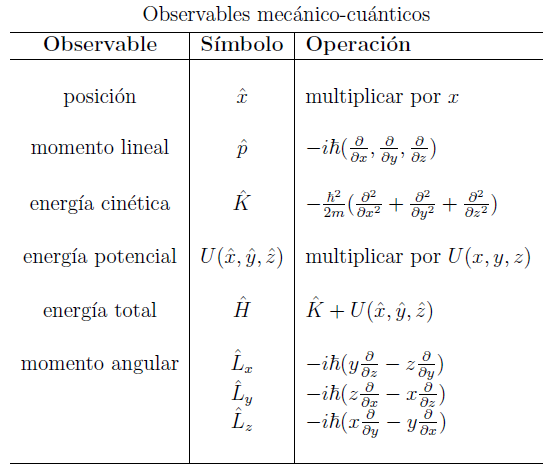

In [ ]:
#@title
Image(filename='OpMecCuan.png', width=590, height=520)

# Partícula en un anillo

Consideremos la partícula de masa $m$, de la figura anterior, viajando en un anillo circular de radio $r$ sobre el plano $x$-$y$. Si su energía potencial es constante (e igual a cero), su Hamiltoniano $\hat{H}$ dependerá solamente de le energía cinética y de acuerdo con la tabla anterior será igual a

$$\hat{H}=-\frac{\hbar^2}{2m}(\frac{\partial^2}{\partial x^2}+\frac{\partial^2}{\partial y^2})$$

Como la partícula está confinada en un anillo circular, el sistema tiene una centro de simetría y por ello el empleo de coordenadas polares puede fascilitar el manejo de las ecuaciones.

En coordenadas polares usamos un punto de referencia llamado polo y una semirecta de referencia que nace en el polo, llamada eje polar, para especificar la posición de un punto $P$. Esta posición está dada por la distancia o radio $r$ del punto al polo y el angulo $\theta$ que forman el eje polar con el radio que une al polo y al punto $P$, como se puede observar en la siguiente figura. 

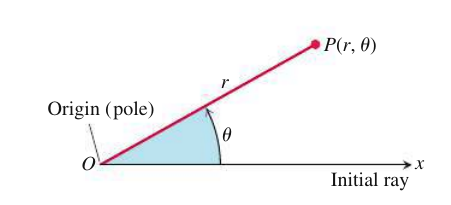

In [ ]:
#@title
Image(filename='polar.png', width=500, height=280)

En coordenadas polares es estándar denotar el ángulo por $\theta$, pero veremos que en sistemas tres dimensionales con un centro de simetría $\theta$ se denotará por $\phi$ (cuando se utilicen coordenadas esféricas). Note que en este sistema de coordenadas la especificación de un punto $P$ en el sistema de coordenadas cartesinas está dada por las ecuaciones $x=rcos\theta$ y $y=rsen\theta$, donde $0\leq \theta < 2\pi$. Al transformar el Hamiltoniano

$$\hat{H}=-\frac{\hbar^2}{2m}(\frac{\partial^2}{\partial x^2}+\frac{\partial^2}{\partial y^2})$$

de nuestro sistema a coordenadas polares tenemos que

$$(\frac{\partial^2}{\partial x^2}+\frac{\partial^2}{\partial y^2})=\frac{\partial^2}{\partial r^2}+\frac{1}{r}\frac{\partial}{\partial r}+\frac{1}{r^2}\frac{\partial^2}{\partial \theta^2}$$

Como el radio del anillo es constante las derivadas paraciales con respecto a el radio son cero y el Hamiltoniano de nuestro sistema se reduce a

$$\hat{H}=-\frac{\hbar^2}{2m}\frac{1}{r^2}\frac{\partial^2}{\partial\theta^2}=-\frac{\hbar^2}{2I}\frac{\partial^2}{\partial\theta^2}$$

Como vemos la función de onda $\Theta$ de la partícula depende sólo de $\theta$, así $\Theta(\theta)$ debe satisfacer la ecuación diferencial

$$\hat{H}\Theta(\theta)=E\Theta(\theta)\Longrightarrow -\frac{\hbar^2}{2I}\frac{\partial^2\Theta}{\partial\theta^2}=E\Theta \Longrightarrow \frac{\partial^2\Theta}{\partial\theta^2}=-\frac{2IE}{\hbar^2}\Theta$$

Como la partícula se mueve en un anillo circular, la función de onda $\Theta$ debe ser periódica, es decir, $\Theta(\theta)=\Theta(\theta+2\pi)$. Con está condición inicial la función de onda estará expresada en términos del número entero $m=0,\pm 1,\pm 2,\pm3,...,$ el cual especificará los posibles estados del sistema. La función de onda del sistema y su correspondiente valor de energía son


$$\Theta_m(\theta)=(\frac{1}{2\pi})^{1/2}[cos(m\theta)+isen(m\theta)] \ \ \ y \ \ \ E_m=\frac{m^2\hbar^2}{2I}$$

La función $EnergiaA(m)$ arroja el valor de energía para un valor permitido de $m$. 

## Ejercicio 1

En la siguiente celda utilice la función $EnergiaA(m)$ para calcular la energía de una partícula confinada en una anillo, cuando:

1. $m=0$
2. $m=2$ y $m=-2$
3. $m=8$ y $m=-8$
4. $m=50$

¿Qué puede observar?

## Ejercicio 2

La función $EnergiaGA(m)$ arroja el gráfico de los valores de energía desde 0 hasta m. En la siguiente celda encuentre los valores de energía para diferentes valores de $m$ y concluya.

En que se diferencian las conclusiones obtenidas con respecto al ejercicio 1.

m= 0 , 0 ; E= 0.0
m= 1 , -1 ; E= 0.5
m= 2 , -2 ; E= 2.0
m= 3 , -3 ; E= 4.5
m= 4 , -4 ; E= 8.0
m= 5 , -5 ; E= 12.5
m= 6 , -6 ; E= 18.0


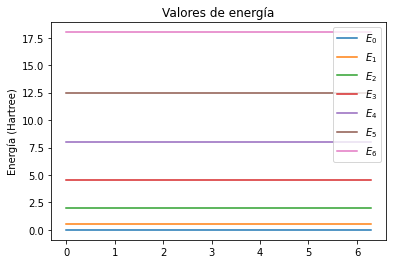

In [ ]:
EnergiaGA(6)

Como las funciones de onda son complejas para $m=\pm 1, \pm 2, \pm 3,...,$ graficaremos solamente su parte real, a través de la función $GfunOA(m)$.

## Ejercicio 3

En la siguiente celda emplee la función $GfunOA(m)$ para graficar la parte real de una partícula confinada en una anillo, cuando:

1. $m=0$
2. $m=1$ y $m=-1$ 
3. $m=2$ y $m=-2$
4. $m=8$ y $m=-8$
5. $m=50$
6. $m=60$

¿Qué puede observar?

Para este sistema el operador de momento angular $\hat{L}$ está dado por $\hat{L}=-i\hbar(y\frac{\partial}{\partial z}-z\frac{\partial}{\partial y},z\frac{\partial}{\partial x}-x\frac{\partial}{\partial z},x\frac{\partial}{\partial y}-y\frac{\partial}{\partial x})$. Como la partícula está confinada al anillo: $z=0$ y $\frac{\partial}{\partial z}=0$, por lo tanto el momento angular es $\hat{L}=\hat{L}_z=(0,0,-i\hbar (x\frac{\partial}{\partial y}-y\frac{\partial}{\partial x}))$ y esta dirigido en la dirección del eje $z$. En coordenadas polares $\hat{L}_z=-i\hbar\frac{\partial}{\partial\theta}$, para nuestro sistema:

$$\hat{L}_z\Theta_m(\theta)=-i\hbar\frac{\partial}{\partial\theta}((\frac{1}{2\pi})^{1/2}[cos(m\theta)+isen(m\theta)])=m\hbar\Theta_m(\theta)$$

Como el momento angular toma los valores $m\hbar$, este es engativo si $m>0$ y es positivo si $m<0$. Para $m=0$ la partícula es estacionaría, mientras que para $m\neq 0$ la partícula puede viajar en dos direcciones diferentes como lo muestra el siguiente diagrama:

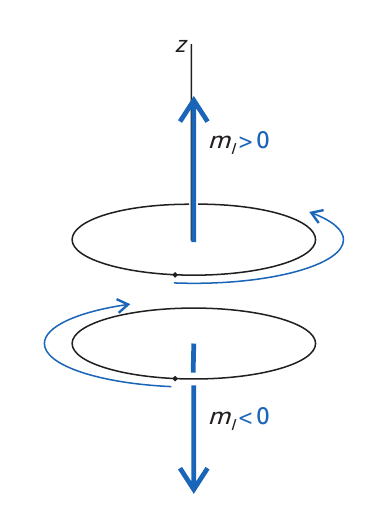

In [ ]:
#@title
Image(filename='Ml.png', width=300, height=500)

En cualquiera de los estados el momento angular esta totalmente definido y la partícula se encuentra uniformemente distribuida a lo largo del anillo, puesto que su función de densidad de probabilidad es uniforme ($|\Theta_m(\theta)|^2=1/2\pi$): la certeza en el momento angular de la partícula implica la incertidumbre total en la localización de la partícula. Es importante notar también que a medida que la energía de la partícula incrementa también incrementan el número de nodos tanto de la parte real como de la parte compleja de la función de onda.

La función $GfunOAC(m)$ gráfica la función de onda en el perímetro del anillo circular para un valor de $m$, junto con la función de densida de probabilidad de la partícula.


## Ejercicio 4

En la siguiente celda utilice la función $GfunOAC(m)$ para diferentes valores de $m$. Concluya y compare las conclusiones obtenidas con aquellas que realizo previamente en el ejercicio $3$.   

## Problema 1

¿Cuál es la probabilidad de que la partícula confinada en un anillo se encuentre entre $\pi/2$ y $\pi$?

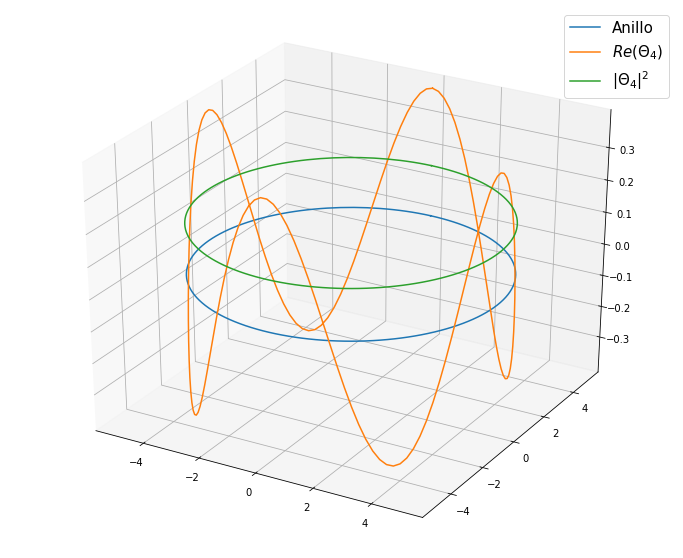

In [ ]:
  GfunOAC(4)

# Bibliografía

Atkins P. y Friedman R., Molecular Quantum Mechanics, Oxford, 2005.

Engel T., Quantum Chemistry and Spectroscopy, Pearson, 1996.